# Chapter 83: Pollution, Climate Policy, Leakage, and Regulatory Instruments

This notebook reruns four worked examples from the chapter: a pollution-haven location choice, the environmental Kuznets curve split into scale, composition and technique, the green paradox, and prices versus quantities. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def location_cost(ordinary, env, delivery):
    """Delivered cost of a plant location: ordinary + environmental + delivery.

    Principle: pollution-haven-hypothesis. Book (ch083): 14.7 + 0.3 + 0.5 = 15.5; 14.7 + 0.3 + 1.2 = 16.2;
    14.7 + 1.8 + 0.5 = 17.0; North 14.0 + 1.8 = 15.8.
    """
    return ordinary + env + delivery


def emissions_decomposition(output, share, int_dirty, int_clean):
    """Emissions E = Y [s i_d + (1 - s) i_c] for a two-sector economy.

    Principle: environmental-kuznets-curve. Book (ch083): 80, 0.45, 2.5, 0.4 gives 107.6;
    140, 0.55 gives 217.7; 220, 0.25, 0.7, 0.2 gives 71.5; 220, 0.25, 2.5, 0.4 gives 203.5.
    """
    return output * (share * int_dirty + (1 - share) * int_clean)


def two_period_extraction(stock, a, t0, t1):
    """Two-period extraction of a fixed stock, zero cost and zero interest, inverse demand p = a - q.

    Principle: green-paradox. Equal net prices a - q0 - t0 = a - (stock - q0) - t1 give
    q0 = (2a - stock + t1 - t0) / 2 (interior case). Book (ch083): stock 100, a 100, t1 20
    gives q0 60, q1 40; equal charges give 50 and 50.
    """
    q0 = (2 * a - stock + t1 - t0) / 2
    q0 = min(max(q0, 0.0), stock)
    q1 = stock - q0
    p0, p1 = a - q0, a - q1
    return {"q0": q0, "q1": q1, "p0": p0, "p1": p1, "net0": p0 - t0, "net1": p1 - t1}


def weitzman_losses(eps, b, c):
    """Local losses from a fixed quantity and a fixed price under a cost shock eps.

    Principle: weitzman-prices-versus-quantities-result. L_Q = eps^2 / (2(b + c)),
    L_P = eps^2 b^2 / (2 c^2 (b + c)). Book (ch083): eps 12, b 2, c 6 gives 9 and 1;
    b 12, c 3 gives 4.8 and 76.8.
    """
    lq = eps ** 2 / (2 * (b + c))
    lp = eps ** 2 * b ** 2 / (2 * c ** 2 * (b + c))
    return {"L_Q": lq, "L_P": lp, "ratio": (b / c) ** 2}


plt.rcParams.update(HOUSE_RC)


trade = SimpleNamespace(location_cost=location_cost)


public = SimpleNamespace(emissions_decomposition=emissions_decomposition, two_period_extraction=two_period_extraction, weitzman_losses=weitzman_losses)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'pollution-haven-hypothesis': {'north_ordinary': 14.0,
                                'north_env': 1.8,
                                'north_total': 15.8,
                                'south_ordinary': 14.7,
                                'south_env': 0.3,
                                'delivery_before': 1.2,
                                'south_before': 16.2,
                                'delivery_after': 0.5,
                                'south_after': 15.5,
                                'margin': 0.3,
                                'south_equal': 17.0},
 'environmental-kuznets-curve': {'output': (80, 140, 220),
                                 'share': (0.45, 0.55, 0.25),
                                 'dirty': 2.5,
                                 'clean': 0.4,
                                 'dirty_high': 0.7,
                                 'clean_high': 0.2,
                                 'E_L': 107.6,
                                 'E_M': 217.7,
                                 'E_H': 71.5,
                                 'E_H_original': 203.5},
 'green-paradox': {'stock': 100, 'a': 100, 't1': 20, 'q0': 60, 'q1': 40, 'q_equal': 50},
 'weitzman-prices-versus-quantities-result': {'eps': 12,
                                              'b': 2,
                                              'c': 6,
                                              'L_Q': 9,
                                              'L_P': 1,
                                              'b2': 12,
                                              'c2': 3,
                                              'L_Q2': 4.8,
                                              'L_P2': 76.8},
 'constructed': {'pollution-haven-hypothesis': {'delivery': [0.85], 'south_env': [1.05]},
                 'environmental-kuznets-curve': {'high_share': [0.45, 0.55]},
                 'green-paradox': {'t1': [10, 30]},
                 'weitzman-prices-versus-quantities-result': {'b': [6]}}}


def bar_tops(ax, xs, values, texts, size=10.5):
    """Value label above each bar."""
    for x, v, t in zip(xs, values, texts):
        ax.annotate(t, (x, v), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=size,
                    color=PALETTE["ink"])


def haven_picture(delivery=0.5, south_env=0.3):
    bv = BV["pollution-haven-hypothesis"]
    n_ord, n_env, s_ord = bv["north_ordinary"], bv["north_env"], bv["south_ordinary"]
    north = trade.location_cost(n_ord, n_env, 0.0)
    south = trade.location_cost(s_ord, south_env, delivery)
    fig, ax = new_figure()
    xs = [0, 1]
    ords, envs, dels = [n_ord, s_ord], [n_env, south_env], [0.0, delivery]
    ax.bar(xs, ords, color=PALETTE["grey"], width=0.55, label="ordinary cost")
    ax.bar(xs, envs, bottom=ords, color=PALETTE["olive"], width=0.55, label="environmental cost")
    ax.bar(xs, dels, bottom=[o + e for o, e in zip(ords, envs)], color=PALETTE["gold"], width=0.55,
           label="delivery cost")
    tie = abs(north - south) < 1e-9
    win = None if tie else (0 if north < south else 1)
    totals = [north, south]
    bar_tops(ax, xs, totals, [f"{num(t, 2)}" + (" (cheaper)" if i == win else "") for i, t in enumerate(totals)])
    ax.set_xticks(xs, ["North", "South"])
    ax.set_ylim(12, 18.6)
    ax.set_xlim(-0.6, 2.2)
    ax.legend(loc="lower right", frameon=False)
    ax.set_xlabel("Plant location")
    ax.set_ylabel("Annual delivered cost ($ million)")
    gap = south - north
    if tie:
        where, short = "The two sites tie", "Tie"
    elif win == 1:
        where, short = f"South is cheaper by {num(-gap, 2)} million, so the plant moves", "South"
    else:
        where, short = f"North is cheaper by {num(gap, 2)} million, so the plant stays", "North"
    metrics = {"North total ($ million)": num(north, 2), "South total ($ million)": num(south, 2),
               "Location": short, "Gap South minus North": num(gap, 2)}
    steps = [f"North = 14.0 + 1.8 = {num(north, 2)}",
             f"South = 14.7 + {num(south_env, 2)} + {num(delivery, 2)} = {num(south, 2)}",
             f"South - North = {num(south, 2)} - {num(north, 2)} = {num(gap, 2)}"]
    interp = (f"North costs 14.0 + 1.8 = {num(north, 2)} million. South costs 14.7 + {num(south_env, 2)} + "
              f"{num(delivery, 2)} = {num(south, 2)} million. {where}. South's ordinary cost is 0.7 million higher, "
              + (f"so any move rests on its environmental-cost advantage of {num(n_env - south_env, 2)} million "
               f"and the delivery cost." if n_env - south_env > 1e-9 else
               "and with equal environmental cost it has no advantage to offset that, so it cannot win."))
    alt = (f"Stacked bars of ordinary, environmental and delivery cost: North {num(north, 2)} million, South "
           f"{num(south, 2)} million with delivery {num(delivery, 2)} and environmental cost {num(south_env, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def kuznets_picture(share=0.25, tech="cleaner"):
    bv = BV["environmental-kuznets-curve"]
    (yl, ym, yh), (sl, sm, _) = bv["output"], bv["share"]
    d, c = bv["dirty"], bv["clean"]
    dh, ch = (bv["dirty_high"], bv["clean_high"]) if tech == "cleaner" else (d, c)
    el = public.emissions_decomposition(yl, sl, d, c)
    em = public.emissions_decomposition(ym, sm, d, c)
    eh = public.emissions_decomposition(yh, share, dh, ch)
    fig, ax = new_figure()
    ax.plot([yl, ym, yh], [el, em, eh], color=PALETTE["navy"], linewidth=2.2, marker="o")
    mark(ax, yl, el, f"low income {num(el, 1)}", col="navy", dx=8, dy=-12, va="top")
    mark(ax, ym, em, f"middle {num(em, 1)}", col="navy", dx=-8, dy=8, ha="right")
    hi_up = eh > em
    mark(ax, yh, eh, f"high {num(eh, 1)}", col="terracotta", dx=-8, dy=8 if hi_up else -10, ha="right",
         va="bottom" if hi_up else "top")
    ax.set_xlim(60, 240)
    ax.set_ylim(0, 380)
    ax.set_xlabel("Output (income stage)")
    ax.set_ylabel("Emissions")
    inverted = eh < em
    metrics = {"E_L": num(el, 1), "E_M": num(em, 1), "E_H": num(eh, 1),
               "Shape": "inverted U" if inverted else "still rising"}
    steps = [f"E_L = 80[0.45(2.5) + 0.55(0.4)] = {num(el, 1)}",
             f"E_M = 140[0.55(2.5) + 0.45(0.4)] = {num(em, 1)}",
             f"E_H = 220[{num(share, 2)}({num(dh, 1)}) + {num(1 - share, 2)}({num(ch, 1)}) = {num(eh, 1)}"]
    steps[2] = steps[2].replace(f"({num(ch, 1)}) =", f"({num(ch, 1)})] =")
    mix = share * dh + (1 - share) * ch
    tech_txt = "cleaner techniques (0.7 and 0.2)" if tech == "cleaner" else "the original techniques (2.5 and 0.4)"
    verdict = (f"Emissions fall from {num(em, 1)} to {num(eh, 1)}, so the path is an inverted U." if inverted else
               f"Emissions keep rising from {num(em, 1)} to {num(eh, 1)}: no inverted U.")
    interp = (f"At high income with dirty share {num(share, 2)} and {tech_txt}, E_H = 220 x "
              f"({num(share, 2)} x {num(dh, 1)} + {num(1 - share, 2)} x {num(ch, 1)}) = 220 x {num(mix, 3)} = "
              f"{num(eh, 1)}. {verdict} Income alone does not turn the curve; composition and technique do.")
    alt = (f"Emissions against output at three income stages: {num(el, 1)} at 80, {num(em, 1)} at 140 and "
           f"{num(eh, 1)} at 220, with high-income dirty share {num(share, 2)} and {tech_txt}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def paradox_picture(t1=20, t0=0):
    bv = BV["green-paradox"]
    stock, a = bv["stock"], bv["a"]
    res = public.two_period_extraction(stock, a, t0, t1)
    q0, q1, p0, p1 = res["q0"], res["q1"], res["p0"], res["p1"]
    fig, ax = new_figure()
    ax.bar([0, 1], [q0, q1], color=[PALETTE["terracotta"], PALETTE["teal"]], width=0.55)
    bar_tops(ax, [0, 1], [q0, q1], [f"q0 = {num(q0, 0)}", f"q1 = {num(q1, 0)}"])
    ax.axhline(50, color=PALETTE["grey"], linestyle="dashed", linewidth=1.4)
    ax.text(0.98, 0.97, "dashed line: no policy, 50 each", transform=ax.transAxes, ha="right", va="top",
            fontsize=10.5, color=PALETTE["grey"])
    for x, p, t in ((0, p0, t0), (1, p1, t1)):
        label(ax, x, 6, f"price {num(p, 0)}\nnet {num(p - t, 0)}", col="ink", dx=0, dy=0, ha="center")
    ax.set_xticks([0, 1], [f"Period 0 (charge {t0})", f"Period 1 (charge {t1})"])
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 82)
    ax.set_xlabel("Period")
    ax.set_ylabel("Units extracted")
    shift = q0 - 50
    metrics = {"q0": num(q0, 0), "q1": num(q1, 0), "p0": num(p0, 0), "p1": num(p1, 0),
               "Net price each period": num(p0 - t0, 0), "Units moved to period 0": num(shift, 0)}
    steps = [f"Net prices equal: 100 - q0 - {t0} = q0 - {t1}",
             f"q0 = (100 + {t1} - {t0}) / 2 = {num(q0, 0)}",
             f"q1 = 100 - {num(q0, 0)} = {num(q1, 0)}",
             f"p0 = 100 - {num(q0, 0)} = {num(p0, 0)}; p1 = 100 - {num(q1, 0)} = {num(p1, 0)}"]
    if shift > 0:
        move = f"Compared with 50 and 50, {num(shift, 0)} units move into period 0 before the heavier later charge"
    elif shift < 0:
        move = f"Compared with 50 and 50, {num(-shift, 0)} units move into period 1, because the charge today is heavier"
    else:
        move = "Equal charges cancel, so extraction stays at 50 in each period, as with no policy"
    unit = "unit" if abs(shift) == 1 else "units"
    move = move.replace(" units", f" {unit}", 1)
    interp = (f"The owner sells where net prices match: 100 - q0 - {t0} = q0 - {t1}, so q0 = (100 + {t1} - {t0}) / 2 "
              f"= {num(q0, 0)} and q1 = {num(q1, 0)}. {move}. Total extraction stays 100.")
    alt = (f"Bars of extraction: {num(q0, 0)} in period 0 and {num(q1, 0)} in period 1, with charges {t0} and {t1}; "
           f"a dashed line marks 50, the no-policy split.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def weitzman_picture(b=2, c=6):
    eps = BV["weitzman-prices-versus-quantities-result"]["eps"]
    res = public.weitzman_losses(eps, b, c)
    lq, lp = res["L_Q"], res["L_P"]
    fig, (ax, bx) = new_figure(2)
    xs = np.linspace(-6.5, 3, 100)
    ax.plot(xs, -b * xs, color=PALETTE["teal"], linewidth=2, label="marginal benefit")
    ax.plot(xs, c * xs, color=PALETTE["navy"], linewidth=1.4, linestyle="dashed", label="expected marginal cost")
    ax.plot(xs, c * xs + eps, color=PALETTE["navy"], linewidth=2, label="marginal cost after +12 shock")
    x_opt, x_tax = -eps / (b + c), -eps / c
    mark(ax, 0, eps, None, col="gold")
    mark(ax, x_tax, 0, None, col="terracotta")
    mark(ax, x_opt, -b * x_opt, None, col="ink")
    vline(ax, 0, "cap", col="gold", y_frac=0.10)
    vline(ax, x_tax, "tax", col="terracotta", y_frac=0.10, ha="right")
    ax.set_xlim(-6.5, 3)
    ax.set_ylim(-20, 32)
    ax.legend(loc="upper left", frameon=False, fontsize=9.5)
    ax.set_xlabel("Abatement minus expected target")
    ax.set_ylabel("Marginal value minus expected level")
    vals = [lp, lq]
    tie = abs(lp - lq) < 1e-9
    cols = [PALETTE["terracotta"], PALETTE["gold"]]
    bx.bar([0, 1], vals, color=cols, width=0.55)
    bar_tops(bx, [0, 1], vals, [num(lp, 1), num(lq, 1)])
    bx.set_xticks([0, 1], ["Price (tax) L_P", "Quantity (cap) L_Q"])
    bx.set_ylim(0, max(vals) * 1.2)
    bx.set_xlim(-0.6, 1.6)
    bx.set_xlabel("Instrument")
    bx.set_ylabel("Welfare loss in either shock state")
    if tie:
        pick, why = "Tie", "the slopes are equal, so the two losses are equal"
    elif lp < lq:
        pick, why = "Price (tax)", "marginal benefit is flatter than marginal cost (b < c), so letting quantity move is cheaper"
    else:
        pick, why = "Quantity (cap)", "marginal benefit is steeper than marginal cost (b > c), so holding quantity is safer"
    metrics = {"L_Q (cap)": num(lq, 1), "L_P (tax)": num(lp, 1), "L_P / L_Q = (b/c)^2": num(res["ratio"], 3),
               "Preferred instrument": pick}
    steps = [f"L_Q = 144 / (2 x ({b} + {c})) = 144 / {2 * (b + c)} = {num(lq, 1)}",
             f"L_P = 144 x {b * b} / (2 x {c * c} x {b + c}) = {144 * b * b:,} / {2 * c * c * (b + c):,} = {num(lp, 1)}",
             f"L_P / L_Q = ({b}/{c})^2 = {num(res['ratio'], 3)}"]
    interp = (f"With shock 12, L_Q = 144 / (2 x {b + c}) = {num(lq, 1)} and L_P = 144 x {b * b} / (2 x {c * c} x "
              f"{b + c}) = {num(lp, 1)}. " + ("The instruments tie: " if tie else f"{pick} wins: ") + why + ".")
    alt = (f"Left: marginal benefit with slope -{b} and marginal cost with slope {c}, shifted up by 12; the cap holds "
           f"abatement at the target, the tax lets it fall to {num(x_tax, 2)}. Right: losses {num(lp, 1)} for the "
           f"tax and {num(lq, 1)} for the cap.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Pollution-haven hypothesis: where does the plant go?

North costs 14.0 of ordinary cost plus 1.8 of environmental cost (\$ million). South costs 14.7 plus 0.3, plus delivery to the market. After a trade agreement cuts delivery to 0.5:

$$K_S=14.7+0.3+0.5=15.5\text{ million dollars},$$

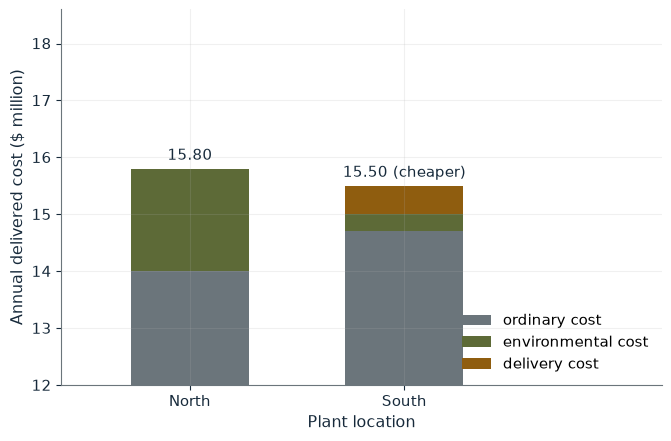

North total ($ million)  15.80
South total ($ million)  15.50
Location                 South
Gap South minus North    -0.30

Worked steps:
  1. North = 14.0 + 1.8 = 15.80
  2. South = 14.7 + 0.30 + 0.50 = 15.50
  3. South - North = 15.50 - 15.80 = -0.30

North costs 14.0 + 1.8 = 15.80 million. South costs 14.7 + 0.30 + 0.50 = 15.50 million. South is cheaper by 0.30 million, so the plant moves. South's ordinary cost is 0.7 million higher, so any move rests on its environmental-cost advantage of 1.50 million and the delivery cost.


In [2]:
show(haven_picture(delivery=0.5, south_env=0.3))

Change one input, `south_env`, and hold the others at the book's values:

In [3]:
sweep(haven_picture, 'south_env', [0.3, 1.05, 1.8], {'delivery': 0.5}, ['South total ($ million)', 'Location'])

south_env | South total ($ million) | Location
0.3 | 15.50 | South
1.05 | 16.25 | North
1.8 | 17.00 | North


South wins by 0.3 million only because of its 1.5 million environmental-cost advantage and the cheaper delivery. With delivery at 1.2 South costs 16.2, and with equal enforcement 17.0: the plant stays North.

## 2. Environmental Kuznets curve: scale, composition and technique

$$E_L=80[0.45(2.5)+0.55(0.4)]=107.6.$$

$$E_M=140[0.55(2.5)+0.45(0.4)]=217.7.$$

$$E_H=220[0.25(0.7)+0.75(0.2)]=71.5.$$

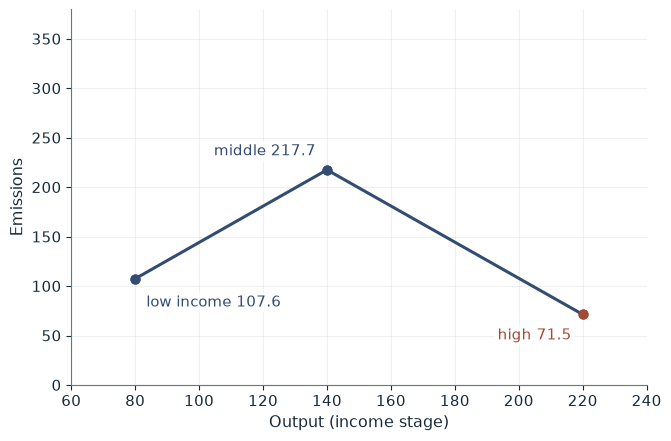

E_L    107.6
E_M    217.7
E_H    71.5
Shape  inverted U

Worked steps:
  1. E_L = 80[0.45(2.5) + 0.55(0.4)] = 107.6
  2. E_M = 140[0.55(2.5) + 0.45(0.4)] = 217.7
  3. E_H = 220[0.25(0.7) + 0.75(0.2)] = 71.5

At high income with dirty share 0.25 and cleaner techniques (0.7 and 0.2), E_H = 220 x (0.25 x 0.7 + 0.75 x 0.2) = 220 x 0.325 = 71.5. Emissions fall from 217.7 to 71.5, so the path is an inverted U. Income alone does not turn the curve; composition and technique do.


In [4]:
show(kuznets_picture(share=0.25, tech='cleaner'))

Change one input, `tech`, and hold the others at the book's values:

In [5]:
sweep(kuznets_picture, 'tech', ['cleaner', 'original'], {'share': 0.25}, ['E_H', 'Shape'])

tech | E_H | Shape
cleaner | 71.5 | inverted U
original | 203.5 | inverted U


With cleaner techniques emissions fall to 71.5 and the path is an inverted U. With the original techniques the same high-income shares give 203.5: most of the cleanup comes from technique.

## 3. Green paradox: an announced future charge

A stock of 100 is sold over two periods with demand $p_t=100-q_t$ and $q_0+q_1=100$. A charge of 20 on producers in period 1 makes net prices equal when

$$100-q_0=q_0-20,$$

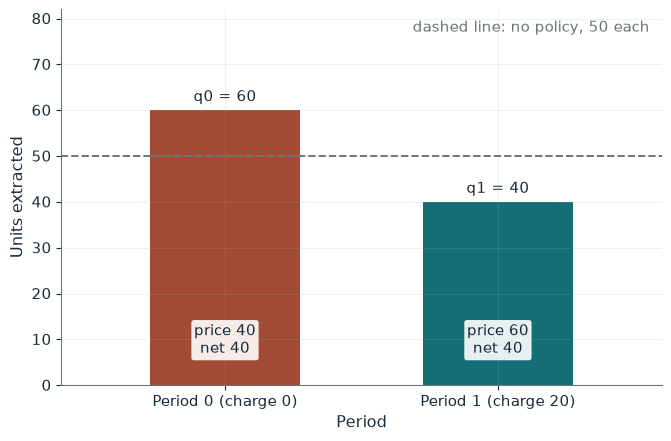

q0                       60
q1                       40
p0                       40
p1                       60
Net price each period    40
Units moved to period 0  10

Worked steps:
  1. Net prices equal: 100 - q0 - 0 = q0 - 20
  2. q0 = (100 + 20 - 0) / 2 = 60
  3. q1 = 100 - 60 = 40
  4. p0 = 100 - 60 = 40; p1 = 100 - 40 = 60

The owner sells where net prices match: 100 - q0 - 0 = q0 - 20, so q0 = (100 + 20 - 0) / 2 = 60 and q1 = 40. Compared with 50 and 50, 10 units move into period 0 before the heavier later charge. Total extraction stays 100.


In [6]:
show(paradox_picture(t1=20, t0=0))

Change one input, `t1`, and hold the others at the book's values:

In [7]:
sweep(paradox_picture, 't1', [0, 10, 20, 30], {'t0': 0}, ['q0', 'q1', 'Net price each period'])

t1 | q0 | q1 | Net price each period
0 | 50 | 50 | 50
10 | 55 | 45 | 45
20 | 60 | 40 | 40
30 | 65 | 35 | 35


Extraction moves forward: 60 now and 40 later instead of 50 and 50. The same charge in both periods (`t0=20`) cancels and restores 50 and 50; total extraction is 100 throughout.

## 4. Weitzman prices versus quantities

$$L_Q(\varepsilon)=\frac{\varepsilon^2}{2(b+c)}.$$

$$L_P(\varepsilon)=\frac{\varepsilon^2b^2}{2c^2(b+c)}.$$

With a shock of 12, $b=2$ and $c=6$:

$$L_Q=\frac{12^2}{2(2+6)}=9.$$

$$L_P=\frac{12^2(2^2)}{2(6^2)(2+6)}=1.$$

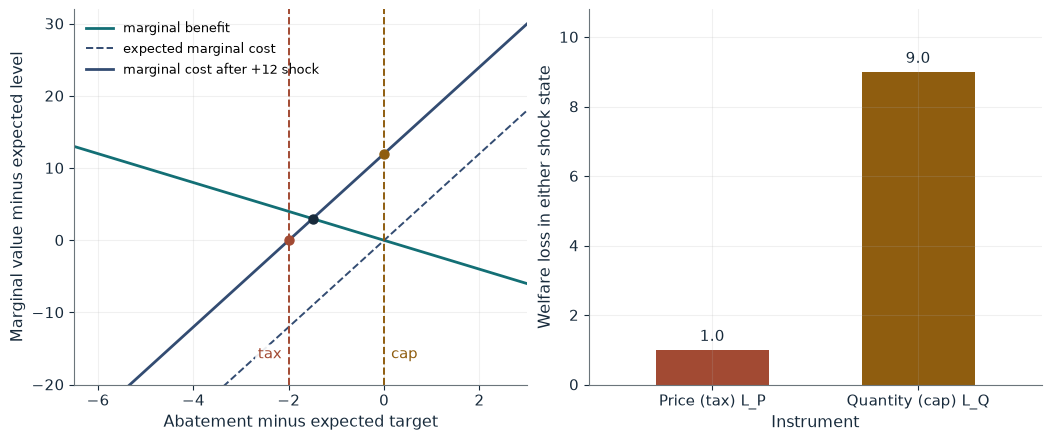

L_Q (cap)             9.0
L_P (tax)             1.0
L_P / L_Q = (b/c)^2   0.111
Preferred instrument  Price (tax)

Worked steps:
  1. L_Q = 144 / (2 x (2 + 6)) = 144 / 16 = 9.0
  2. L_P = 144 x 4 / (2 x 36 x 8) = 576 / 576 = 1.0
  3. L_P / L_Q = (2/6)^2 = 0.111

With shock 12, L_Q = 144 / (2 x 8) = 9.0 and L_P = 144 x 4 / (2 x 36 x 8) = 1.0. Price (tax) wins: marginal benefit is flatter than marginal cost (b < c), so letting quantity move is cheaper.


In [8]:
show(weitzman_picture(b=2, c=6))

Change one input, `b`, and hold the others at the book's values:

In [9]:
sweep(weitzman_picture, 'b', [2, 6, 12], {'c': 6}, ['L_Q (cap)', 'L_P (tax)', 'Preferred instrument'])

b | L_Q (cap) | L_P (tax) | Preferred instrument
2 | 9.0 | 1.0 | Price (tax)
6 | 6.0 | 6.0 | Tie
12 | 4.0 | 16.0 | Quantity (cap)


A flat marginal benefit (b < c) favors the tax: its loss is one ninth of the cap's. With b = 12 and c = 3 (`b=12, c=3`) the losses are 76.8 for the tax and 4.8 for the cap.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

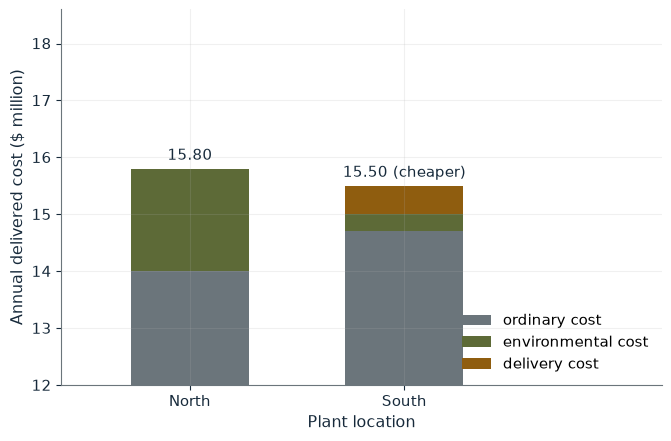

North total ($ million)  15.80
South total ($ million)  15.50
Location                 South
Gap South minus North    -0.30

Worked steps:
  1. North = 14.0 + 1.8 = 15.80
  2. South = 14.7 + 0.30 + 0.50 = 15.50
  3. South - North = 15.50 - 15.80 = -0.30

North costs 14.0 + 1.8 = 15.80 million. South costs 14.7 + 0.30 + 0.50 = 15.50 million. South is cheaper by 0.30 million, so the plant moves. South's ordinary cost is 0.7 million higher, so any move rests on its environmental-cost advantage of 1.50 million and the delivery cost.


In [10]:
show(haven_picture(delivery=0.5, south_env=0.3))

## Practice

**1.** At delivery 0.5 and South environmental cost 1.05, what is South's total, and where does the plant go?

<details><summary>Answer</summary>

14.7 + 1.05 + 0.5 = 16.25, above North's 15.8, so the plant stays North.

</details>

**2.** With a period 1 charge of 30 and none in period 0, what are q0 and q1?

<details><summary>Answer</summary>

100 - q0 = q0 - 30, so q0 = 65 and q1 = 35.

</details>

**3.** At b = 6 and c = 6, what are L_Q and L_P?

<details><summary>Answer</summary>

L_Q = 144 / 24 = 6 and L_P = 144 x 36 / (2 x 36 x 12) = 6: a tie.

</details>